In [ ]:
import pandas as pd
import numpy as np
import re
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pandas.errors import SettingWithCopyWarning
from econml.dml import LinearDML
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MultiLabelBinarizer




warnings.simplefilter("ignore", SettingWithCopyWarning)

LOAD DATASETES

In [11]:
# BoardGameGeek dataset
bgg_dataset = pd.read_csv("bgg_dataset.csv", sep=';')

# Product/edition dataset
df = pd.read_csv('products_with_edition.csv')
df = df.drop(columns=['price_in_usd'])  # Remove unnecessary column

CLEAN PRODUCT DATA

In [12]:
cols_to_keep = ["objectid", "price", "version_name", "condition"]
products_clean = df.loc[:, cols_to_keep].copy()

# Drop missing IDs/prices
products_clean = products_clean.dropna(subset=["objectid", "price"])

# Convert types
products_clean["objectid"] = pd.to_numeric(products_clean["objectid"], errors="coerce").astype('Int64')
products_clean["price"] = pd.to_numeric(products_clean["price"], errors="coerce")

# Standardize condition
products_clean["condition"] = products_clean["condition"].astype(str).str.lower().str.strip()

# Keep only 'new' condition
products_clean = products_clean[products_clean["condition"] == "new"]

# Clean version names
products_clean["version_name"] = products_clean["version_name"].astype(str).str.strip()

# Remove duplicates
products_clean = products_clean.drop_duplicates(subset=["objectid", "version_name", "condition", "price"])

# Average price for duplicate versions
products_clean_avg = products_clean.groupby(
    ["objectid", "version_name", "condition"], as_index=False
)["price"].mean()

# IQR-based outlier removal
Q1 = products_clean_avg["price"].quantile(0.25)
Q3 = products_clean_avg["price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

products_model_ready = products_clean_avg[
    (products_clean_avg["price"] >= lower_bound) & 
    (products_clean_avg["price"] <= upper_bound)
]

CLEAN BGG DATA

In [13]:
# Numeric conversion
numeric_cols = ['Year Published', 'Rating Average', 'Complexity Average', 'BGG Rank']
int_cols = ['Min Players', 'Max Players', 'Play Time', 'Min Age', 'Users Rated', 'Owned Users']

for col in numeric_cols:
    bgg_dataset[col] = pd.to_numeric(bgg_dataset[col].astype(str).str.replace(',', '.'), errors='coerce')
for col in int_cols:
    bgg_dataset[col] = pd.to_numeric(bgg_dataset[col], errors='coerce')

# Strip text
for col in ['Name', 'Mechanics', 'Domains']:
    bgg_dataset[col] = bgg_dataset[col].astype(str).str.strip()

# Drop rows with missing values
bgg_cleaned = bgg_dataset.dropna().copy()

MERGE PRODUCT DATA WITH BGG DATA

In [14]:
bgg_cleaned['ID'] = pd.to_numeric(bgg_cleaned['ID'], errors='coerce')
products_model_ready['objectid'] = pd.to_numeric(products_model_ready['objectid'], errors='coerce')

# Filter products in BGG
products_model_ready = products_model_ready[products_model_ready['objectid'].isin(bgg_cleaned['ID'])]

# Aggregate by version
products_grouped = products_model_ready.groupby(['objectid', 'version_name'], as_index=False).agg({
    'price': 'mean',
    'condition': 'first'
})

# Merge
bgg_merged = bgg_cleaned.merge(
    products_grouped[['objectid', 'price', 'condition', 'version_name']],
    how='left', left_on='ID', right_on='objectid'
)
bgg_merged.drop(columns=['objectid'], inplace=True)

# Clean unrealistic values
bgg_merged = bgg_merged[
    (bgg_merged['Year Published'] >= 1900) &
    (bgg_merged['Min Players'] > 0) &
    (bgg_merged['Max Players'] <= 20) &
    (bgg_merged['Play Time'] <= 600) &
    (bgg_merged['Min Age'] >= 0) &
    ((bgg_merged['price'].isna()) | (bgg_merged['price'] <= 300))
]

bgg_final = bgg_merged.dropna(subset=['price', 'version_name', 'condition'])
bgg_final.rename(columns={'BGG Rank': 'Success Rank'}, inplace=True)

DATA PREPROCESSING AND LABELING

In [15]:
# Complexity label
bgg_final["complexity_label"] = pd.cut(
    bgg_final["Complexity Average"], bins=[0, 2, 3.5, 5],
    labels=["Easy", "Medium", "Hard"], include_lowest=True
)

# High rating flag
bgg_final["highly_rated"] = bgg_final["Rating Average"] >= 8

# Game type classification
def classify_game_type(domains):
    if pd.isna(domains):
        return "Unknown"
    d = domains.lower()
    strategy_keywords = ["strategy", "abstract", "war", "wargame", "economic"]
    thematic_keywords = ["thematic", "adventure", "fantasy", "horror", "science fiction", "story", "exploration"]
    family_keywords = ["family", "children", "party", "puzzle", "dexterity", "trivia"]
    is_strategy = any(k in d for k in strategy_keywords)
    is_thematic = any(k in d for k in thematic_keywords)
    is_family = any(k in d for k in family_keywords)
    if is_strategy and is_thematic: return "Hybrid"
    elif is_strategy: return "Strategy"
    elif is_thematic: return "Thematic"
    elif is_family: return "Family/Party"
    else: return "Other"

bgg_final["game_type"] = bgg_final["Domains"].apply(classify_game_type)

# Price category
bgg_final["price_category"] = pd.cut(
    bgg_final["price"], bins=[0, 20, 50, 100, 500, 1000],
    labels=["very low", "low", "medium", "high", "very high"]
)

# Value-for-money features
bgg_final["rating_per_dollar"] = bgg_final["Rating Average"] / bgg_final["price"]
bgg_final["complexity_per_dollar"] = bgg_final["Complexity Average"] / bgg_final["price"]

# Mechanic annotation
mechanic_map = {
    "dice-driven": ["dice", "roll", "yahtzee"],
    "worker-placement": ["worker placement", "placement"],
    "deck-building": ["deck building", "deckbuilding"],
    "drafting": ["draft", "card drafting"],
    "tile-placement": ["tile placement", "domino", "polyomino"],
    "area-control": ["area control", "area majority"],
    "resource-management": ["resource", "economy", "produce"],
    "engine-building": ["engine", "combo", "synergy"],
    "set-collection": ["set collection"],
    "hand-management": ["hand management"],
    "card-based": ["card", "deck", "hand"],
    "co-op": ["cooperative", "co-op", "team"],
    "campaign-legacy": ["legacy", "campaign", "scenario"],
    "hidden-information": ["hidden", "secret", "deduction"],
    "bluffing": ["bluff", "traitor"],
    "puzzle": ["puzzle", "logic"],
    "party": ["party", "social"],
    "conflict-combat": ["combat", "fight", "battle"],
    "trading-negotiation": ["trade", "negotiation"]
}

def annotate_mechanics(text):
    if pd.isna(text):
        return ["other"]
    parts = [p.strip().lower() for p in text.split(",")]
    matched = set()
    for part in parts:
        for label, keywords in mechanic_map.items():
            if any(kw in part for kw in keywords):
                matched.add(label)
    return list(matched) if matched else ["other"]

bgg_final["Mechanics_annotated"] = bgg_final["Mechanics"].apply(annotate_mechanics)

# Explode for analysis
bgg_exploded = bgg_final.explode("Mechanics_annotated")

bgg_model_ready = bgg_final.drop(
    columns=["Name", "Mechanics", "Domains"]
)



FINAL DATASETS

In [16]:
bgg_final.to_csv("bgg_final.csv", index=False)
bgg_model_ready.to_csv("bgg_model_ready.csv", index=False)
bgg_exploded.to_csv("bgg_mechanics_exploded.csv", index=False)

print("All datasets saved successfully")
print("Model-ready dataset shape:", bgg_model_ready.shape)
print("Final BGG dataset shape:", bgg_final.shape)
print("Exploded mechanics dataset shape:", bgg_exploded.shape)

All datasets saved successfully
Model-ready dataset shape: (22794, 21)
Final BGG dataset shape: (22794, 24)
Exploded mechanics dataset shape: (49031, 24)


EDA: EXPLORATORY DATA ANALYSIS


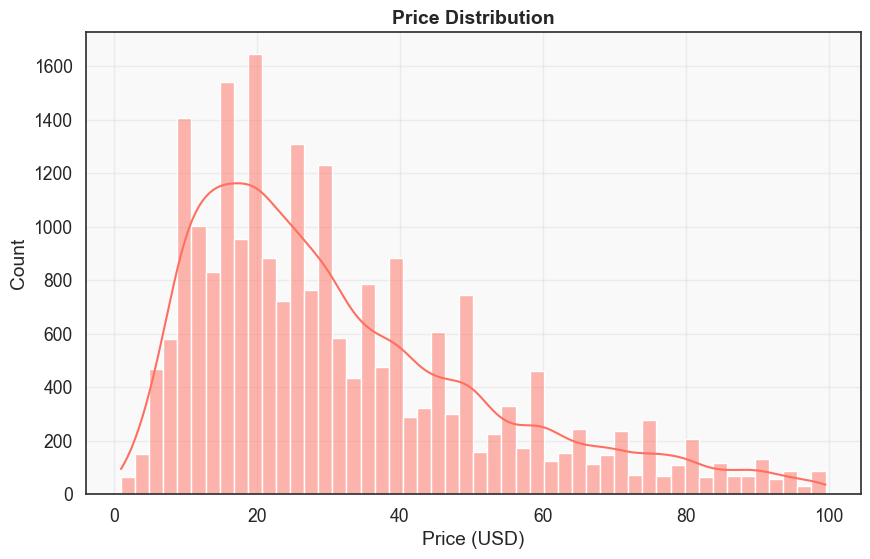

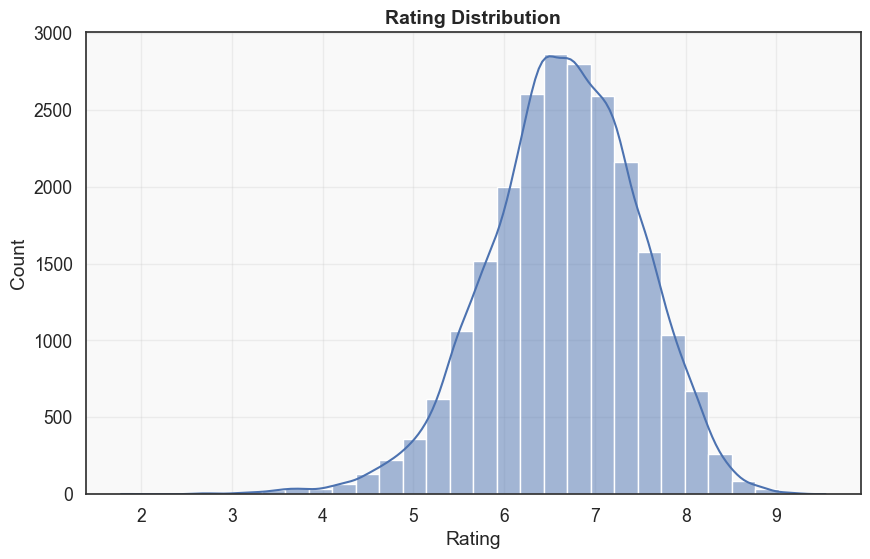

C:\Users\Abdel\AppData\Local\Temp\ipykernel_5620\640981396.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


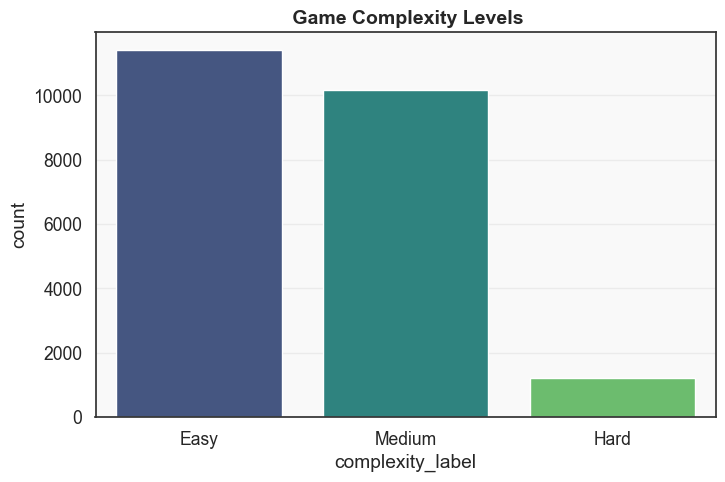

C:\Users\Abdel\AppData\Local\Temp\ipykernel_5620\640981396.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


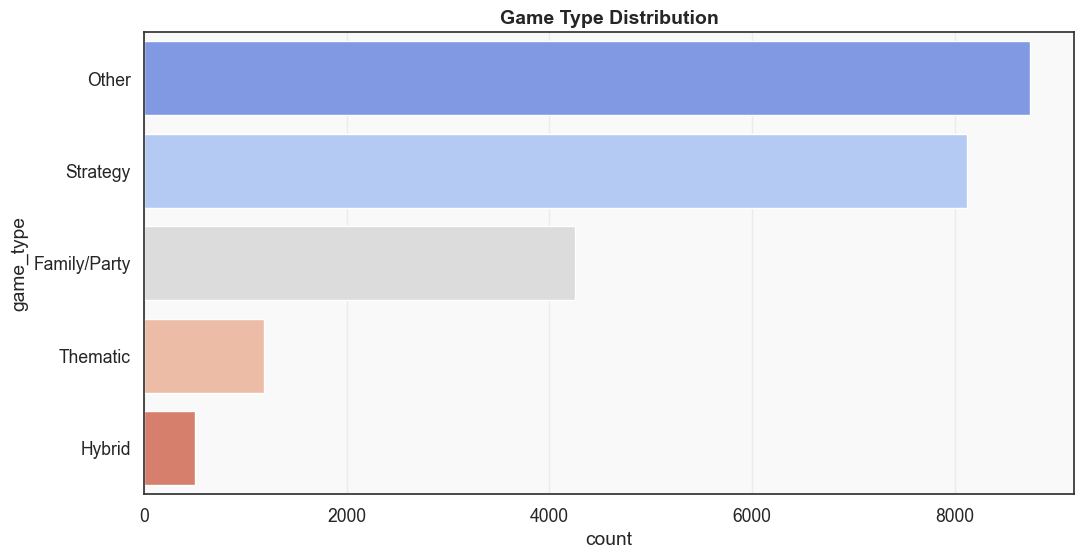

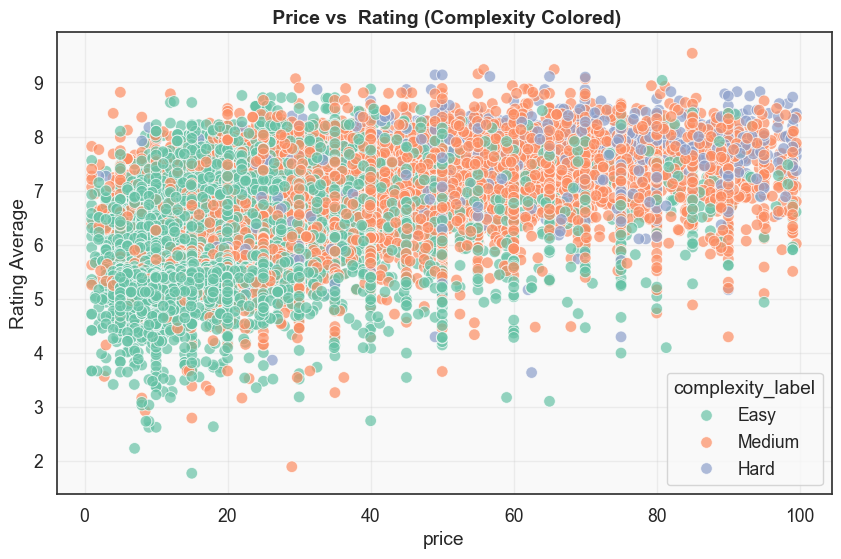

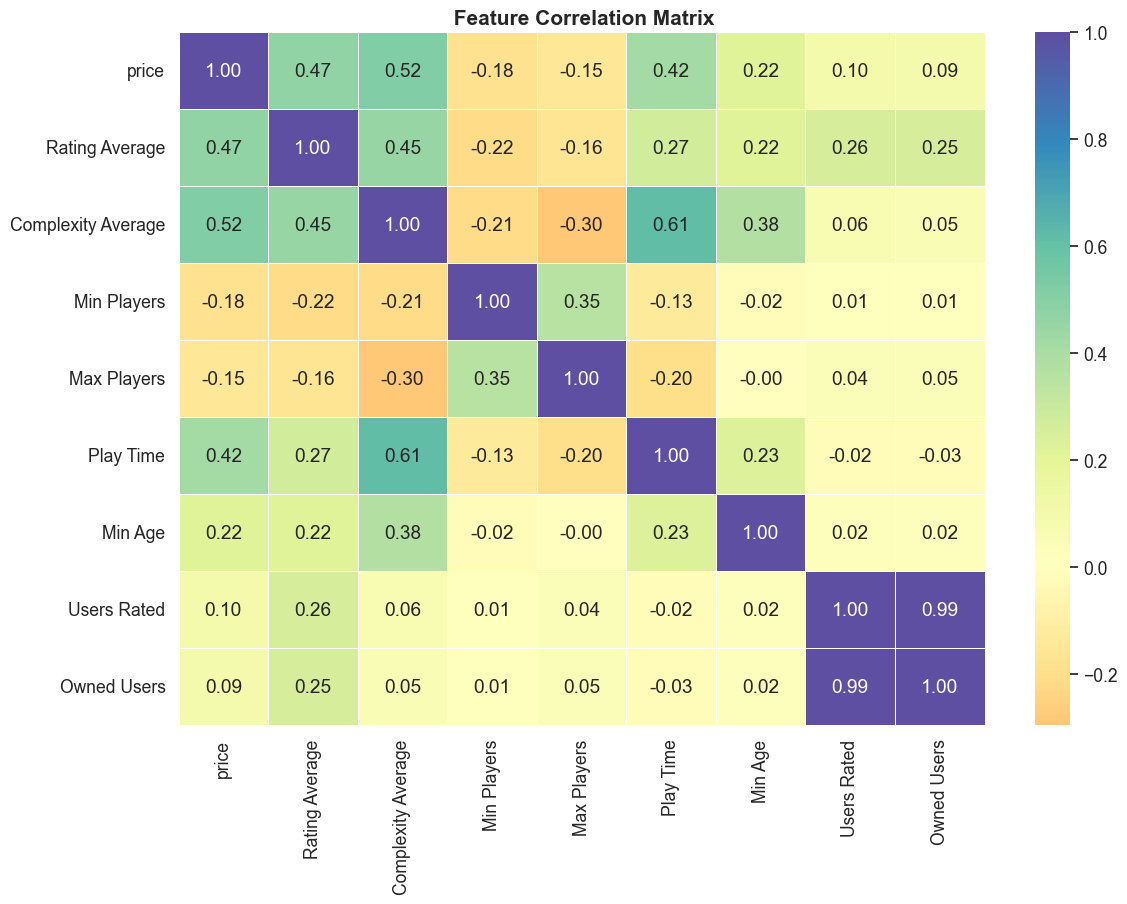

C:\Users\Abdel\AppData\Local\Temp\ipykernel_5620\640981396.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


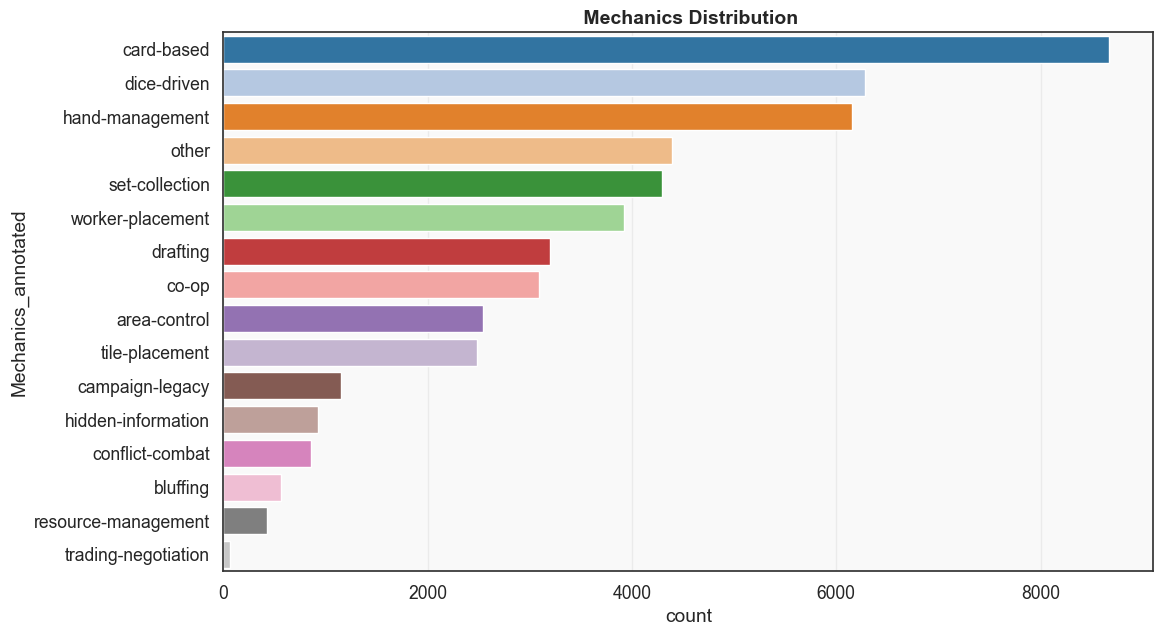

C:\Users\Abdel\AppData\Local\Temp\ipykernel_5620\640981396.py:113: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


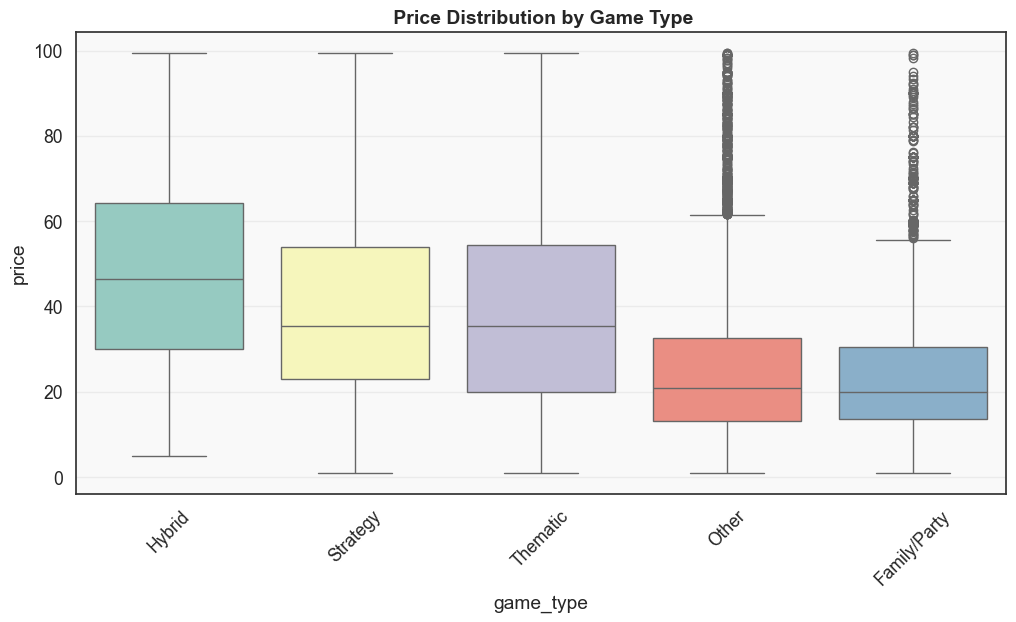

C:\Users\Abdel\AppData\Local\Temp\ipykernel_5620\640981396.py:127: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


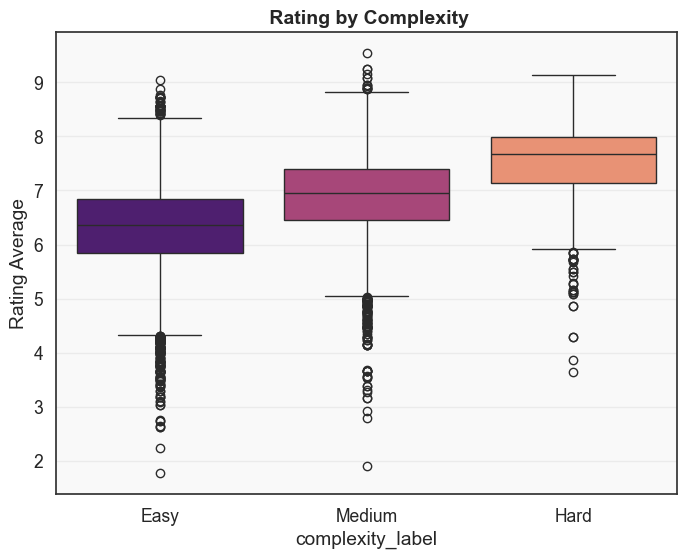

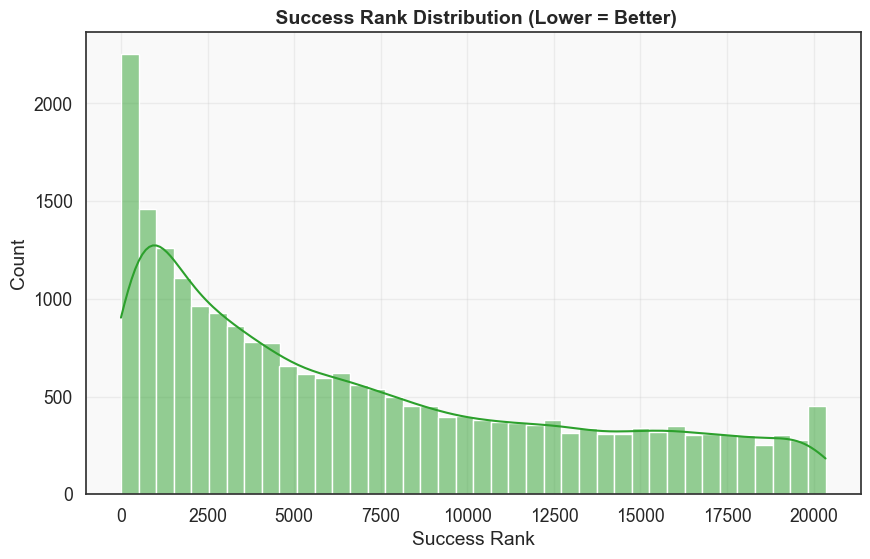

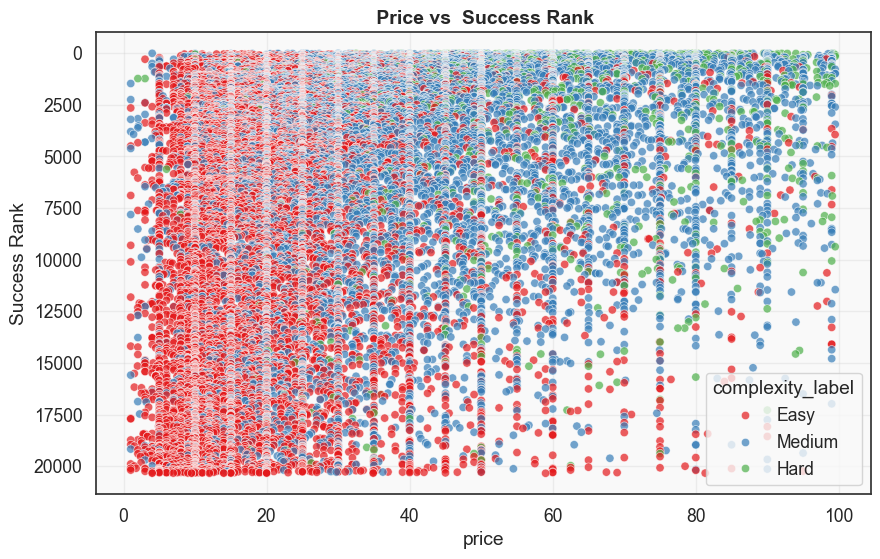

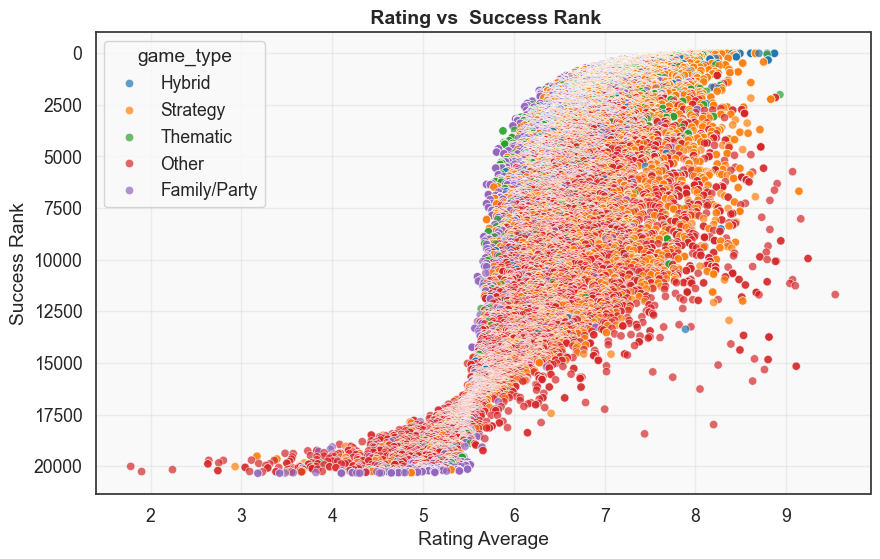

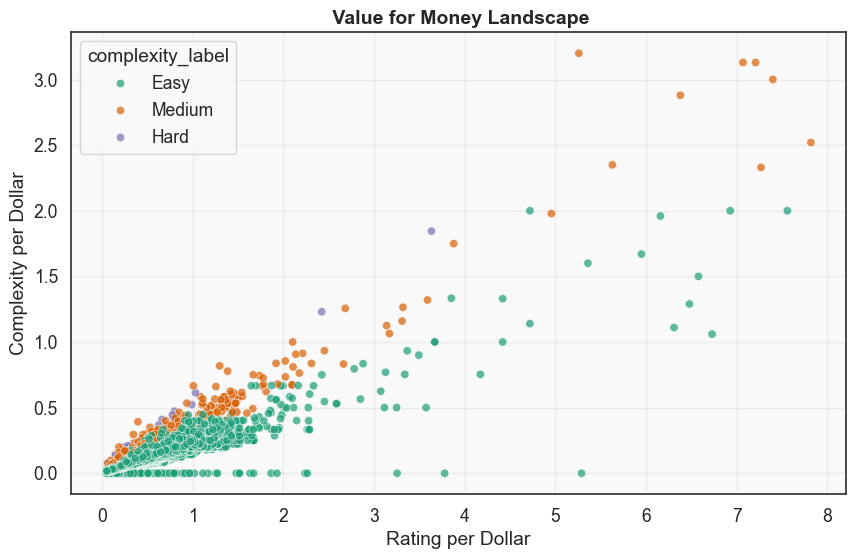

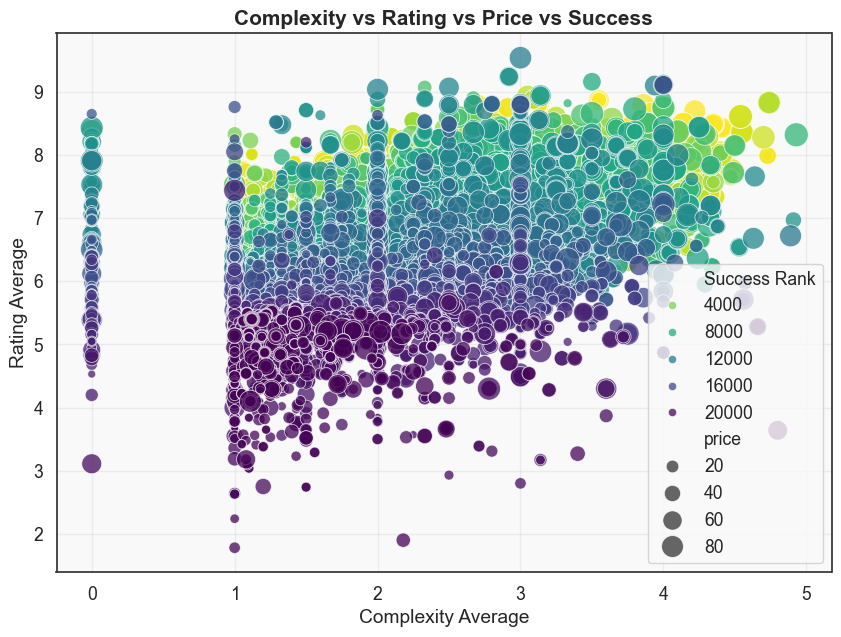

C:\Users\Abdel\AppData\Local\Temp\ipykernel_5620\640981396.py:216: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


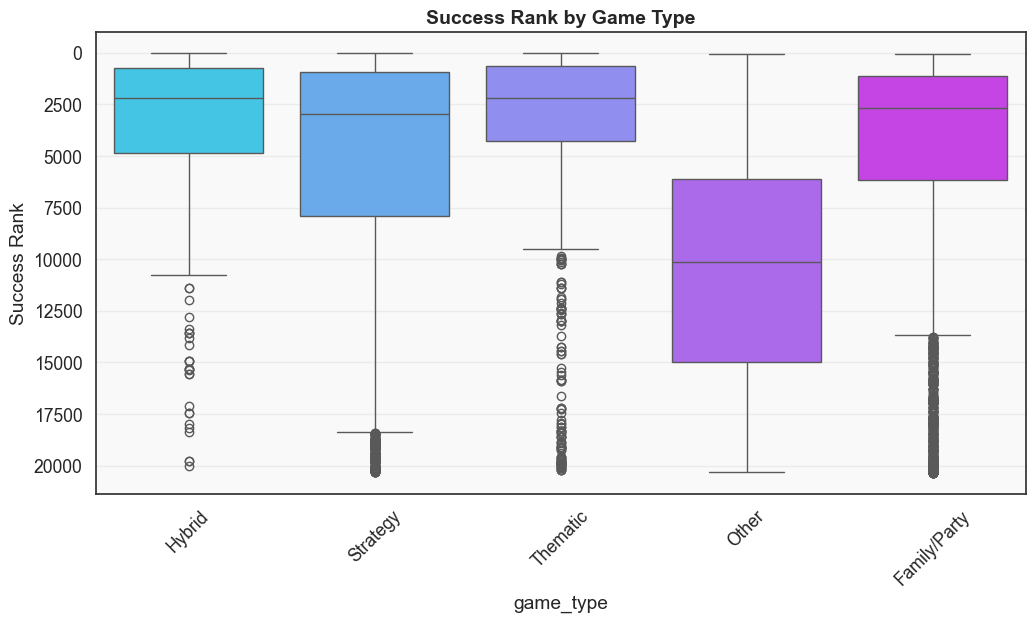

In [ ]:

sns.set_theme(
    style="whitegrid",
    palette="Spectral",
    font_scale=1.15,
    rc={
        "axes.facecolor": "#f9f9f9",
        "grid.alpha": 0.3,
        "axes.edgecolor": "0.2",
        "figure.facecolor": "white"
    }
)


# PRICE DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final['price'], bins=50, kde=True, color="#ff6f61")
plt.title("Price Distribution", fontsize=14, weight="bold")
plt.xlabel("Price (USD)")
plt.ylabel("Count")
plt.show()


#  RATING DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final['Rating Average'], bins=30, kde=True, color="#4c72b0")
plt.title("Rating Distribution", fontsize=14, weight="bold")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()


# COMPLEXITY LABEL

plt.figure(figsize=(8,5))
sns.countplot(
    x="complexity_label",
    data=bgg_final,
    order=["Easy","Medium","Hard"],
    palette="viridis"
)
plt.title(" Game Complexity Levels", fontsize=14, weight="bold")
plt.show()


#  GAME TYPE DISTRIBUTION

plt.figure(figsize=(12,6))
sns.countplot(
    y="game_type",
    data=bgg_final,
    order=bgg_final["game_type"].value_counts().index,
    palette="coolwarm"
)
plt.title("Game Type Distribution", fontsize=14, weight="bold")
plt.show()


#  PRICE vs RATING

plt.figure(figsize=(10,6))
sns.scatterplot(
    x="price",
    y="Rating Average",
    hue="complexity_label",
    palette="Set2",
    data=bgg_final,
    alpha=0.7,
    s=70
)
plt.title(" Price vs  Rating (Complexity Colored)", fontsize=14, weight="bold")
plt.show()

 
# CORRELATION HEATMAP

numeric_cols = [
    "price", "Rating Average", "Complexity Average", 
    "Min Players", "Max Players", "Play Time", 
    "Min Age", "Users Rated", "Owned Users"
]

plt.figure(figsize=(13,9))
sns.heatmap(
    bgg_final[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="Spectral",
    center=0,
    linewidths=0.6
)
plt.title(" Feature Correlation Matrix", fontsize=15, weight="bold")
plt.show()


#  MECHANICS DISTRIBUTION

plt.figure(figsize=(12,7))
sns.countplot(
    y="Mechanics_annotated",
    data=bgg_exploded,
    order=bgg_exploded["Mechanics_annotated"].value_counts().index,
    palette="tab20"
)
plt.title(" Mechanics Distribution", fontsize=14, weight="bold")
plt.show()


#  PRICE BY GAME TYPE

plt.figure(figsize=(12,6))
sns.boxplot(
    x="game_type",
    y="price",
    data=bgg_final,
    palette="Set3"
)
plt.xticks(rotation=45)
plt.title(" Price Distribution by Game Type", fontsize=14, weight="bold")
plt.show()


#  RATING BY COMPLEXITY

plt.figure(figsize=(8,6))
sns.boxplot(
    x="complexity_label",
    y="Rating Average",
    data=bgg_final,
    order=["Easy","Medium","Hard"],
    palette="magma"
)
plt.title(" Rating by Complexity", fontsize=14, weight="bold")
plt.show()


#  SUCCESS RANK DISTRIBUTION

plt.figure(figsize=(10,6))
sns.histplot(bgg_final["Success Rank"], bins=40, kde=True, color="#2ca02c")
plt.title(" Success Rank Distribution (Lower = Better)", fontsize=14, weight="bold")
plt.xlabel("Success Rank")
plt.show()


#  PRICE vs SUCCESS RANK

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=bgg_final,
    x="price",
    y="Success Rank",
    hue="complexity_label",
    palette="Set1",
    alpha=0.7
)
plt.gca().invert_yaxis()
plt.title(" Price vs  Success Rank", fontsize=14, weight="bold")
plt.show()


#  RATING vs SUCCESS RANK

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=bgg_final,
    x="Rating Average",
    y="Success Rank",
    hue="game_type",
    palette="tab10",
    alpha=0.7
)
plt.gca().invert_yaxis()
plt.title(" Rating vs  Success Rank", fontsize=14, weight="bold")
plt.show()


# VALUE FOR MONEY

plt.figure(figsize=(10,6))
sns.scatterplot(
    x="rating_per_dollar",
    y="complexity_per_dollar",
    hue="complexity_label",
    palette="Dark2",
    data=bgg_final,
    alpha=0.7
)
plt.title(" Value for Money Landscape", fontsize=14, weight="bold")
plt.xlabel("Rating per Dollar")
plt.ylabel("Complexity per Dollar")
plt.show()


# ULTIMATE BUBBLE CHART

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=bgg_final,
    x="Complexity Average",
    y="Rating Average",
    size="price",
    hue="Success Rank",
    palette="viridis_r",
    sizes=(30, 300),
    alpha=0.75
)
plt.title("Complexity vs Rating vs Price vs Success", fontsize=15, weight="bold")
plt.show()


#  SUCCESS BY GAME TYPE

plt.figure(figsize=(12,6))
sns.boxplot(
    data=bgg_final,
    x="game_type",
    y="Success Rank",
    palette="cool"
)
plt.gca().invert_yaxis()
plt.xticks(rotation=45)
plt.title("Success Rank by Game Type", fontsize=14, weight="bold")
plt.show()


Causal Inference: Success Rank

In [29]:


# 1 Numeric confounders and treatments

numeric_cols = bgg_model_ready.select_dtypes(include=np.number).columns.tolist()
numeric_treatments = ['Rating Average', 'Complexity Average', 'price', 'Year Published', 'Min Players']
outcome = 'Success Rank'
numeric_confounders = list(set(numeric_cols) - set(numeric_treatments) - {outcome})

X_num = bgg_model_ready[numeric_confounders]

# Scale numeric confounders
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

# Convert scaled numeric features to DataFrame to align indices safely
X_num_scaled_df = pd.DataFrame(X_num_scaled, columns=numeric_confounders, index=bgg_model_ready.index)


#  Categorical confounders

categorical_cols = ['game_type', 'price_category']  # only single-value categorical
bgg_categorical = bgg_model_ready.dropna(subset=categorical_cols + ['Mechanics_annotated'])

# One-hot encode standard categorical columns
ohe = OneHotEncoder(drop='first', sparse_output=False)
X_cat_basic = ohe.fit_transform(bgg_categorical[categorical_cols])
X_cat_basic = pd.DataFrame(X_cat_basic, columns=ohe.get_feature_names_out(), index=bgg_categorical.index)

# Multi-label encode 'Mechanics_annotated'
mlb = MultiLabelBinarizer()
X_mechanics = mlb.fit_transform(bgg_categorical['Mechanics_annotated'])
X_mechanics = pd.DataFrame(X_mechanics, columns=mlb.classes_, index=bgg_categorical.index)

# Combine categorical features
X_cat = pd.concat([X_cat_basic, X_mechanics], axis=1)


#  Combine numeric and categorical confounders

X_num_scaled_aligned = X_num_scaled_df.loc[bgg_categorical.index].values
X_combined = np.hstack([X_num_scaled_aligned, X_cat.values])


#  Treatments and outcome
T = bgg_categorical[numeric_treatments]
Y = bgg_categorical[outcome]


# 5Fit LinearDML

model_y = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
model_t = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)

dml = LinearDML(model_y=model_y, model_t=model_t, discrete_treatment=False, random_state=42)
dml.fit(Y=Y, T=T, X=X_combined)


# Compute Average Treatment Effects (ATE)

effects = {}
for treatment in T.columns:
    dml_single = LinearDML(model_y=model_y, model_t=model_t, discrete_treatment=False, random_state=42)
    dml_single.fit(Y=Y, T=T[[treatment]], X=X_combined)
    te = dml_single.effect(X=X_combined)
    effects[treatment] = te.mean()


#  Display results

print("Causal Effects on Success Rank (Numeric + Categorical Confounders):")
for k, v in effects.items():
    print(f"{k}: {v:.4f}")


C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\Abdel\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed whe

Causal Effects on Success Rank (Numeric + Categorical Confounders):
Rating Average: -3729.1088
Complexity Average: -1449.4188
price: -643.7472
Year Published: -205.5543
Min Players: 63.5575


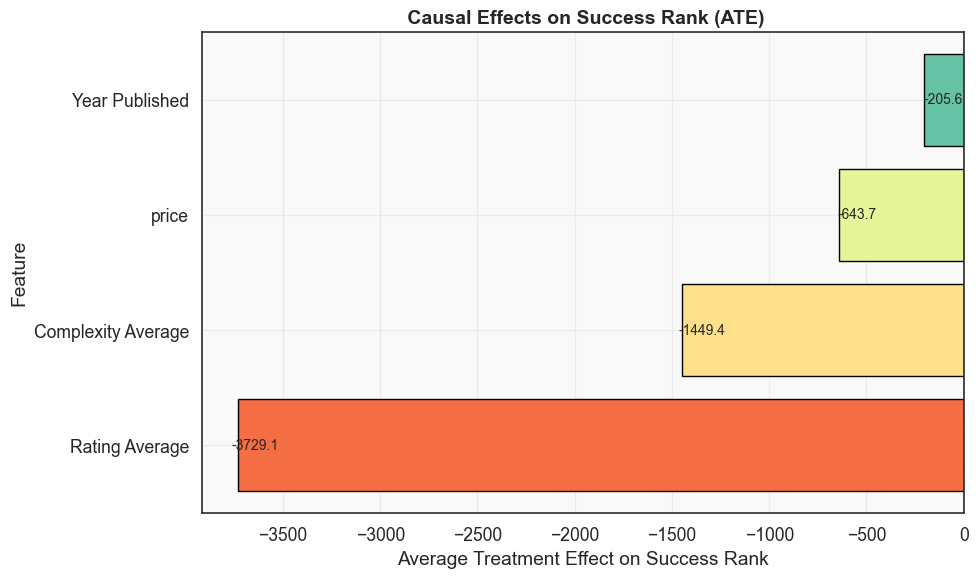

In [28]:



#  Causal Results

causal_results = {
    "Rating Average": -3729.1088,
    "Complexity Average":-1449.4188,
    "price": -643.7472,
    "Year Published": -205.5543,
    
}

df_causal = pd.DataFrame.from_dict(
    causal_results, orient="index", columns=["ATE"]
).sort_values("ATE")


# BAR PLOT

plt.figure(figsize=(10, 6))

colors = sns.color_palette("Spectral", len(df_causal))

bars = plt.barh(
    df_causal.index,
    df_causal["ATE"],
    color=colors,
    edgecolor="black"
)

# Zero line
plt.axvline(0, color="black", linestyle="--", linewidth=1)

# Labels on bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width * 1.01 if width < 0 else width * 1.01,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        va="center",
        fontsize=10
    )

plt.title(" Causal Effects on Success Rank (ATE)", fontsize=14, weight="bold")
plt.xlabel("Average Treatment Effect on Success Rank")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

